<a href="https://colab.research.google.com/github/edavidbustosp/AplicacionesDeepLearning/blob/main/DeteccionFraude.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Detección de Fraude Mediante Deep Learning**
Proyecto desarrollado por:

Ing. Edgar David Bustos Pulido

Aplicaciones de Deep Learning



#**Primer Avance**

Implementación inicial del modelo,

* Pruebas experimentales

* Análisis de resultados

* Propuesta de rediseño.


Importación de Librerías

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)


Configuraciones

In [2]:
#Configuración de visualización
sns.set_theme(style="whitegrid")

#Configuración de reproducibilidad

SEED=42

np.random.seed(SEED)
torch.manual_seed(SEED)

#Dispositivo de ejecución
device=torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo de ejecución: ", device)
print("Versión de Pythorch: ", torch.__version__)


Dispositivo de ejecución:  cpu
Versión de Pythorch:  2.14.1+cpu


Carga del dataset

In [3]:
from google.colab import files
from io import BytesIO

uploaded=files.upload()

archivo=next(iter(uploaded))

df=pd.read_csv(BytesIO(uploaded[archivo]))

print("Dataset cargado correctamente")
print("Dimensiones: ",df.shape)

display(df.head())

Saving creditcard.csv to creditcard.csv
Dataset cargado correctamente
Dimensiones:  (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


#**Analisis Exploratorio Inicial**

Información general del dataset
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19

/tmp/ipykernel_1202/202824329.py:39: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  distribucion.idex=["Legitimas (0)", "Fraudulentas (1)"]


,Cantidad,Porcentaje
Class,,
0,284315,99.827251
1,492,0.172749


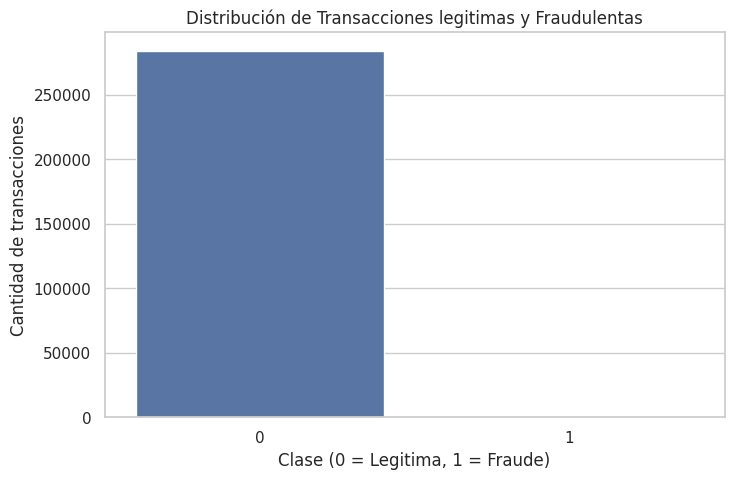


Estadísticas descriptivas
--------------------------------------------------


,Time,Amount
count,284807.000000,284807.000000
mean,94813.859575,88.349619
std,47488.145955,250.120109
min,0.000000,0.000000
25%,54201.500000,5.600000
50%,84692.000000,22.000000
75%,139320.500000,77.165000
max,172792.000000,25691.160000


In [6]:
# ======================================
# ANÁLISIS EXPLORATORIO DEL DATASET
# ======================================

#1. Información general

print("Información general del dataset")
print("-" * 50)

df.info()


#2. Verificación de valores nulos

print("\nValores Nulos")
print("-" * 50)

print("Total de valores nulos: ", df.isnull().sum().sum())

#3. Verificación de registros duplicados

print("\nRegistros duplicados")
print("-" * 50)

print("Cantidad de duplicados: ", df.duplicated().sum())

#4. Distribución de las clases
print("\nDistribución de las clases")
print("-" * 50)

conteo_clases=df["Class"].value_counts().sort_index()
porcentaje_clases=df["Class"].value_counts(normalize=True).sort_index()*100

distribucion=pd.DataFrame({
    "Cantidad":conteo_clases,
    "Porcentaje":porcentaje_clases
})

distribucion.idex=["Legitimas (0)", "Fraudulentas (1)"]

display(distribucion)

#5. Validación del desequilibrio
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Class"
)

plt.title("Distribución de Transacciones legitimas y Fraudulentas")
plt.xlabel("Clase (0 = Legitima, 1 = Fraude)")
plt.ylabel("Cantidad de transacciones")

plt.show()


#6. Estadísticas descriptivas
print("\nEstadísticas descriptivas")
print("-" * 50)

display(df[["Time", "Amount"]].describe())

